# IT3091 Machine Learning — Group DS-67
## Telco Customer Churn — Final Notebook
**Guided Data Track · Telecommunications (7)**  
**Primary lens:** Churn Risk · **Secondary lens:** High Risk Customer Profiling




## Workflow



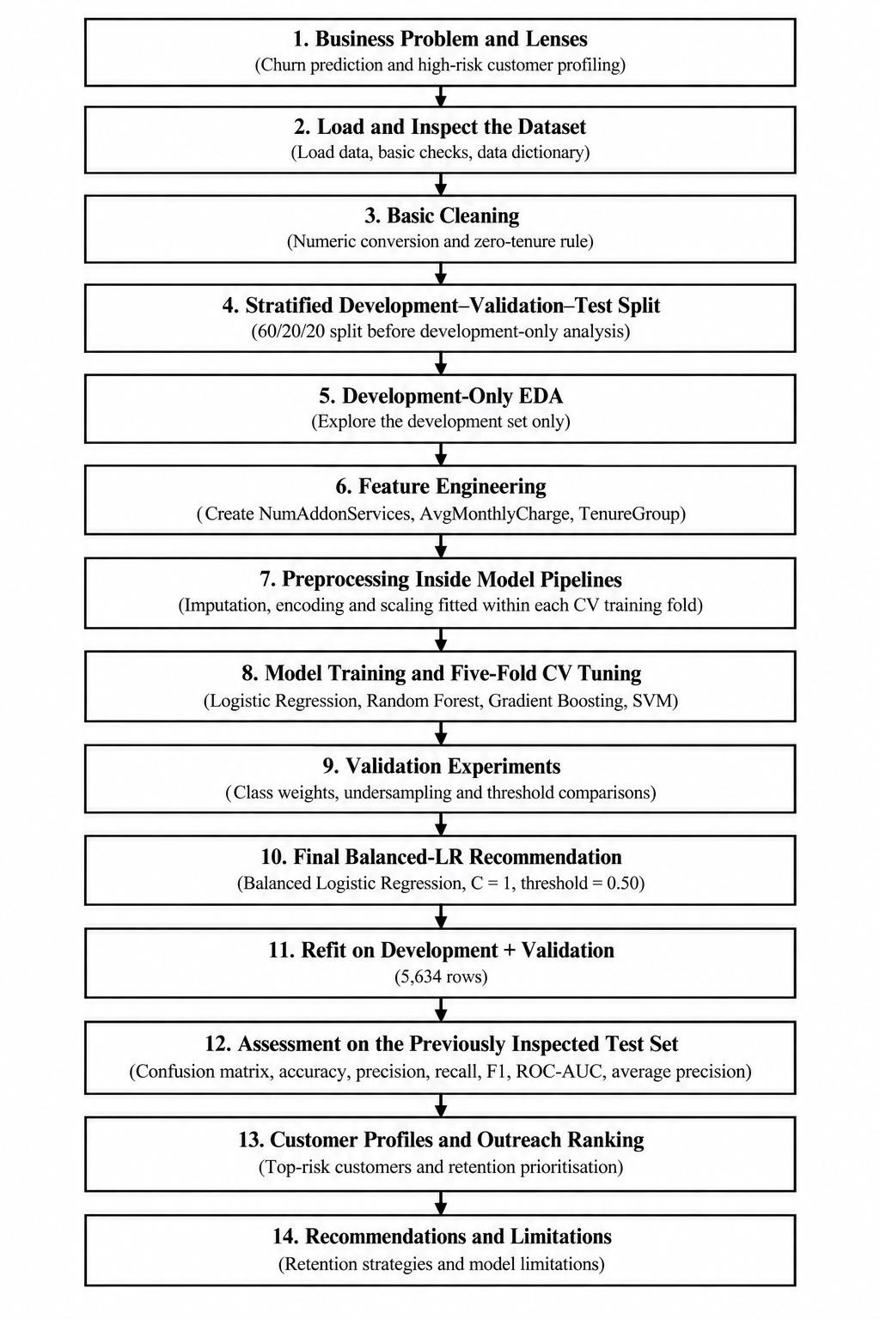


## Import libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.inspection import permutation_importance

SEED = 42
sns.set_theme(style='whitegrid')
from sklearn.base import clone
# Keep complete tables visible in the saved notebook.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

## Load the dataset




In [2]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print('Rows and columns:', df.shape)
display(df.head())

Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print('Missing values:')
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customer IDs:', df['customerID'].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Basic cleaning

Convert `TotalCharges` to numeric; blank strings become missing. Set missing charges to 0 when tenure is 0.


In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

display(df.loc[df['TotalCharges'].isnull(), ['tenure', 'MonthlyCharges', 'TotalCharges']])

df.loc[(df['TotalCharges'].isnull()) & (df['tenure'] == 0), 'TotalCharges'] = 0
df = df.drop_duplicates()

print('Missing values after cleaning:')
print(df.isnull().sum())

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


Missing values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


## Train/validation/test split

Stratified outer 80/20 test split; then 75/25 development/validation from the training pool (~60/20/20 overall).


In [5]:
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})

X_pool, X_test, y_pool, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_pool, y_pool, test_size=0.25, random_state=SEED, stratify=y_pool
)

print('Development rows for EDA, CV and fitting:', len(X_train))
print('Validation rows for experiment/threshold selection:', len(X_validation))
print('Test rows for final assessment:', len(X_test))
print('Development churn proportion:', y_train.mean())

Development rows for EDA, CV and fitting: 4225
Validation rows for experiment/threshold selection: 1409
Test rows for final assessment: 1409
Development churn proportion: 0.26532544378698225


## Training only EDA


In [6]:
train_data = X_train.copy()
train_data['Churn'] = y_train

print(train_data['Churn'].value_counts())
print(train_data['Churn'].value_counts(normalize=True))
display(train_data[['tenure', 'MonthlyCharges', 'TotalCharges']].describe())

Churn
0    3104
1    1121
Name: count, dtype: int64
Churn
0    0.734675
1    0.265325
Name: proportion, dtype: float64


,tenure,MonthlyCharges,TotalCharges
count,4225.000000,4225.000000,4225.000000
mean,32.294438,64.776462,2284.044781
std,24.667945,29.989186,2280.333668
min,0.000000,18.400000,0.000000
25%,9.000000,35.750000,383.650000
50%,29.000000,70.400000,1380.100000
75%,56.000000,89.750000,3825.850000
max,72.000000,118.750000,8684.800000


### Numerical distributions and outliers


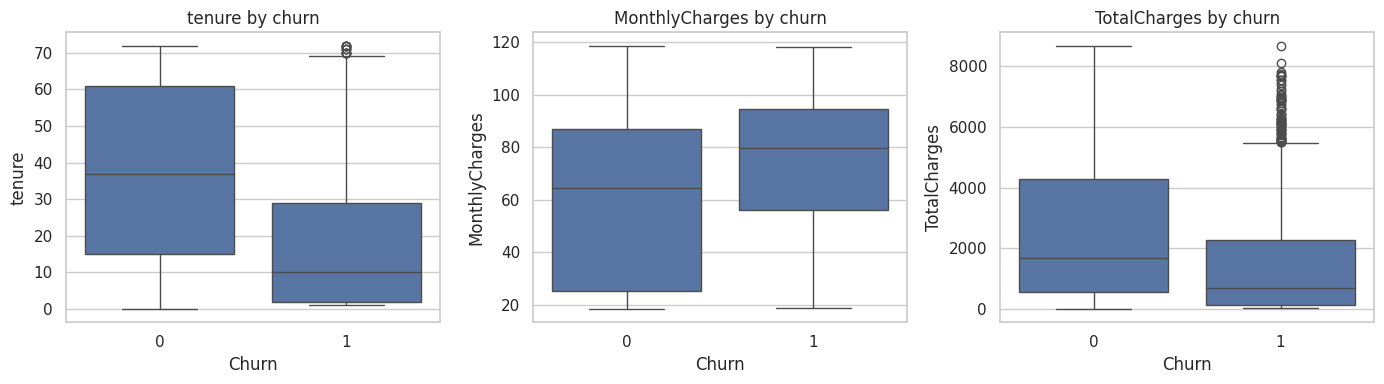

In [7]:
numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for column, ax in zip(numeric_columns, axes):
    sns.boxplot(data=train_data, x='Churn', y=column, ax=ax)
    ax.set_title(column + ' by churn')
plt.tight_layout()
plt.show()

In [8]:
outlier_results = []

for column in numeric_columns:
    Q1 = train_data[column].quantile(0.25)
    Q3 = train_data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((train_data[column] < lower) | (train_data[column] > upper)).sum()
    outlier_results.append([column, lower, upper, count])

outlier_table = pd.DataFrame(outlier_results, columns=['Column', 'Lower bound', 'Upper bound', 'Flagged values'])
display(outlier_table)

,Column,Lower bound,Upper bound,Flagged values
0,tenure,-61.50,126.50,0
1,MonthlyCharges,-45.25,170.75,0
2,TotalCharges,-4779.65,8989.15,0


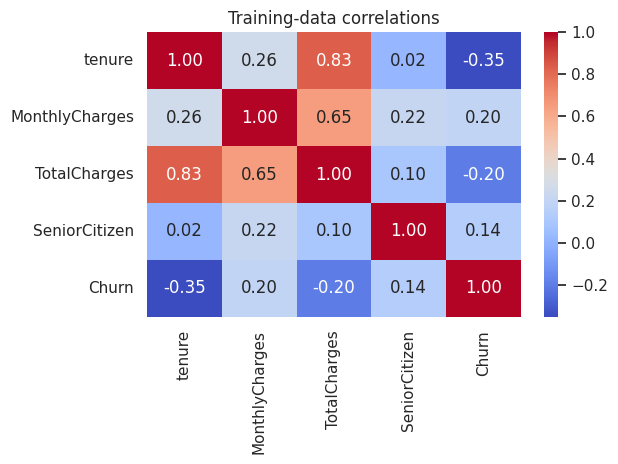

In [9]:
correlations = train_data[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']].corr()
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Training-data correlations')
plt.tight_layout()
plt.show()

### Categorical analysis


In [10]:
categorical_columns = X_train.select_dtypes(exclude='number').columns
category_results = []

for column in categorical_columns:
    summary = train_data.groupby(column)['Churn'].agg(['count', 'mean']).reset_index()
    summary.columns = ['Category', 'Accounts', 'Churn proportion']
    summary['Column'] = column
    category_results.append(summary)

categorical_summary = pd.concat(category_results, ignore_index=True)
display(categorical_summary[['Column', 'Category', 'Accounts', 'Churn proportion']])

,Column,Category,Accounts,Churn proportion
0,gender,Female,2086,0.270853
1,gender,Male,2139,0.259935
2,Partner,No,2189,0.333486
3,Partner,Yes,2036,0.192043
4,Dependents,No,2968,0.315701
5,Dependents,Yes,1257,0.146380
6,PhoneService,No,430,0.258140
7,PhoneService,Yes,3795,0.266140
8,MultipleLines,No,2015,0.247643
9,MultipleLines,No phone service,430,0.258140


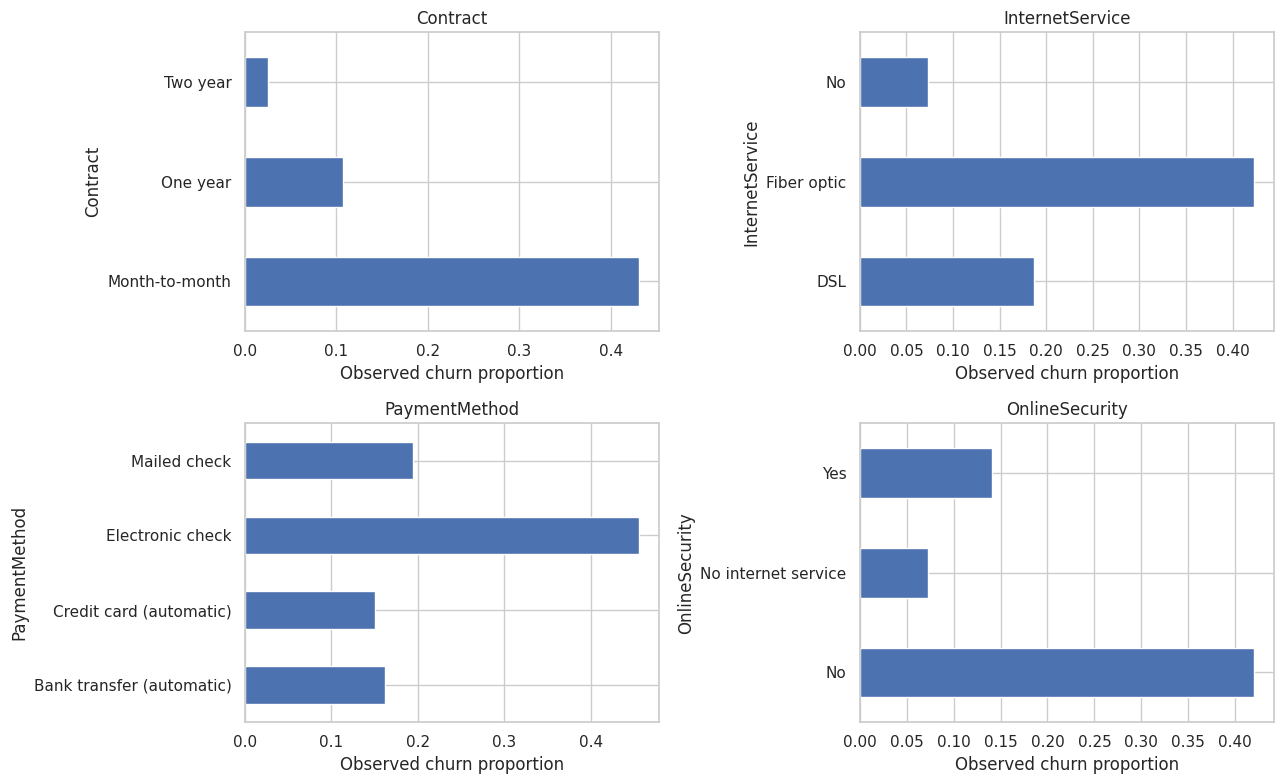

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for column, ax in zip(['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity'], axes.ravel()):
    churn_rates = train_data.groupby(column)['Churn'].mean()
    churn_rates.plot(kind='barh', ax=ax)
    ax.set_title(column)
    ax.set_xlabel('Observed churn proportion')

plt.tight_layout()
plt.show()

### Consolidated EDA insight log


In [12]:
contract_rates = train_data.groupby('Contract')['Churn'].mean()
internet_rates = train_data.groupby('InternetService')['Churn'].mean()
payment_rates = train_data.groupby('PaymentMethod')['Churn'].mean()
tenure_medians = train_data.groupby('Churn')['tenure'].median()

eda_log = pd.DataFrame({
    'Observation': ['Class imbalance', 'Tenure difference', 'Contract pattern', 'Internet pattern', 'Payment pattern', 'Charge/tenure correlation'],
    'Evidence': [
        f'Training churn proportion: {y_train.mean():.1%}',
        f'Median tenure: Stay={tenure_medians[0]}, Churn={tenure_medians[1]}',
        f'Highest churn proportion: {contract_rates.idxmax()} ({contract_rates.max():.1%})',
        f'Highest churn proportion: {internet_rates.idxmax()} ({internet_rates.max():.1%})',
        f'Highest churn proportion: {payment_rates.idxmax()} ({payment_rates.max():.1%})',
        f'TotalCharges vs tenure correlation: {correlations.loc["TotalCharges", "tenure"]:.3f}'
    ],
    'Implication': [
        'Use metrics beyond accuracy; compare class weighting',
        'Include tenure and investigate early customer support',
        'Include contract; explore voluntary contract review',
        'Include service type; investigate service experience',
        'Include payment method; avoid causal assumptions',
        'Interpret correlated features cautiously; correlation alone does not justify removal'
    ]
})
display(eda_log)

,Observation,Evidence,Implication
0,Class imbalance,Training churn proportion: 26.5%,Use metrics beyond accuracy; compare class weighting
1,Tenure difference,"Median tenure: Stay=37.0, Churn=10.0",Include tenure and investigate early customer support
2,Contract pattern,Highest churn proportion: Month-to-month (43.1%),Include contract; explore voluntary contract review
3,Internet pattern,Highest churn proportion: Fiber optic (42.3%),Include service type; investigate service experience
4,Payment pattern,Highest churn proportion: Electronic check (45.6%),Include payment method; avoid causal assumptions
5,Charge/tenure correlation,TotalCharges vs tenure correlation: 0.834,Interpret correlated features cautiously; correlation alone does not justify removal


## 9. Feature engineering

Derived features: `NumAddonServices`, `AvgMonthlyCharge`, `TenureGroup`. Also simplify “No internet/phone service” labels.


In [13]:
def add_features(data):
    data = data.copy()
    data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
    data.loc[(data['TotalCharges'].isnull()) & (data['tenure'] == 0), 'TotalCharges'] = 0

    service_columns = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                       'TechSupport', 'StreamingTV', 'StreamingMovies']
    data['NumAddonServices'] = (data[service_columns] == 'Yes').sum(axis=1)

    data['AvgMonthlyCharge'] = data['TotalCharges'] / data['tenure'].replace(0, np.nan)
    data.loc[data['tenure'] == 0, 'AvgMonthlyCharge'] = 0

    data['TenureGroup'] = pd.cut(data['tenure'],
        bins=[-1, 6, 12, 24, 48, np.inf],
        labels=['0-6m', '7-12m', '13-24m', '25-48m', '>48m']).astype(object)

    for column in service_columns + ['MultipleLines']:
        data[column] = data[column].replace({'No internet service': 'No', 'No phone service': 'No'})

    return data

In [14]:
X_train = add_features(X_train)
X_validation = add_features(X_validation)
X_test = add_features(X_test)

display(X_train[['tenure', 'TotalCharges', 'NumAddonServices', 'AvgMonthlyCharge', 'TenureGroup']].head())

,tenure,TotalCharges,NumAddonServices,AvgMonthlyCharge,TenureGroup
2312,18,401.85,0,22.325000,13-24m
5227,7,639.70,2,91.385714,7-12m
6404,52,5731.40,5,110.219231,>48m
88,46,927.10,0,20.154348,25-48m
6496,40,4086.30,3,102.157500,25-48m


## Feature decisions and preprocessing

| Decision | Method |
|---|---|
| Missing numeric | Median imputer (training-fitted) |
| Missing categories | Most-frequent imputer (training-fitted) |
| Categories | One-hot encoding |
| Scaling | StandardScaler for LR/SVM; none for trees |
| Outliers | Inspect with IQR; retain |
| Gender | Audit only (excluded from predictors) |
| Class imbalance | Compare weights / undersampling later; no SMOTE |


In [15]:
numeric_features = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
                    'NumAddonServices', 'AvgMonthlyCharge']

categorical_features = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines',
    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
    'PaperlessBilling', 'PaymentMethod', 'TenureGroup']

numeric_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

numeric_unscaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_preparation = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocess_scaled = ColumnTransformer([
    ('numeric', numeric_scaled, numeric_features),
    ('categorical', categorical_preparation, categorical_features)
])

preprocess_tree = ColumnTransformer([
    ('numeric', numeric_unscaled, numeric_features),
    ('categorical', categorical_preparation, categorical_features)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

### Feature engineering evidence

Compare original predictors vs original + derived features (fixed balanced LR, development CV).


In [16]:
original_numeric = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
original_categorical = categorical_features[:-1]  # original categories without TenureGroup

preprocess_original = ColumnTransformer([
    ('numeric', numeric_scaled, original_numeric),
    ('categorical', categorical_preparation, original_categorical)
])

original_reference = Pipeline([
    ('preprocess', preprocess_original),
    ('model', LogisticRegression(C=1, class_weight='balanced', solver='liblinear', max_iter=1000, random_state=SEED))
])

engineered_reference = Pipeline([
    ('preprocess', preprocess_scaled),
    ('model', LogisticRegression(C=1, class_weight='balanced', solver='liblinear', max_iter=1000, random_state=SEED))
])

original_f1 = cross_val_score(original_reference, X_train, y_train, cv=cv, scoring='f1')
engineered_f1 = cross_val_score(engineered_reference, X_train, y_train, cv=cv, scoring='f1')

feature_comparison = pd.DataFrame({
    'Feature set': ['Original predictors', 'Original + three derived features'],
    'Mean CV F1': [original_f1.mean(), engineered_f1.mean()],
    'Fold standard deviation': [original_f1.std(), engineered_f1.std()]
})
display(feature_comparison)
print('Change in mean CV F1:', engineered_f1.mean() - original_f1.mean())

,Feature set,Mean CV F1,Fold standard deviation
0,Original predictors,0.635900,0.017398
1,Original + three derived features,0.635958,0.010619


Change in mean CV F1: 5.7360002761575046e-05


## Majority **class** baseline


In [17]:
dummy = DummyClassifier(strategy='most_frequent')
baseline_scores = cross_validate(dummy, X_train, y_train, cv=cv, scoring=['accuracy', 'recall', 'f1'])

print('Baseline CV accuracy:', baseline_scores['test_accuracy'].mean())
print('Baseline CV recall:', baseline_scores['test_recall'].mean())
print('Baseline CV F1:', baseline_scores['test_f1'].mean())

Baseline CV accuracy: 0.7346745562130177
Baseline CV recall: 0.0
Baseline CV F1: 0.0


## Model strategy and tuning

| Model | Role |
|---|---|
| Logistic Regression | Interpretable learning baseline |
| Random Forest | Bagged trees |
| Gradient Boosting | Sequential trees |
| RBF SVM | Nonlinear margin model |

Tuning uses development nly `GridSearchCV` with F1.


### Logistic Regression


In [18]:
lr_pipeline = Pipeline([
    ('preprocess', preprocess_scaled),
    ('model', LogisticRegression(solver='liblinear', max_iter=1000, random_state=SEED))
])

lr_default_scores = cross_validate(lr_pipeline, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'])
lr_default_f1 = lr_default_scores['test_f1'].mean()
lr_default_accuracy = lr_default_scores['test_accuracy'].mean()

lr_parameters = {
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}

lr_search = GridSearchCV(lr_pipeline, lr_parameters, cv=cv, scoring='f1')
lr_search.fit(X_train, y_train)

print('Default CV accuracy:', lr_default_accuracy)
print('Default CV F1:', lr_default_f1)
print('Selected parameters:', lr_search.best_params_)
print('Best tuning CV F1:', lr_search.best_score_)

Default CV accuracy: 0.8071005917159763
Default CV F1: 0.5955069166113606
Selected parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best tuning CV F1: 0.6359577632710297


###  Random Forest


In [19]:
rf_pipeline = Pipeline([
    ('preprocess', preprocess_tree),
    ('model', RandomForestClassifier(n_estimators=100, random_state=SEED))
])

rf_default_scores = cross_validate(rf_pipeline, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'])
rf_default_f1 = rf_default_scores['test_f1'].mean()
rf_default_accuracy = rf_default_scores['test_accuracy'].mean()

rf_parameters = {
    'model__max_depth': [6, 10],
    'model__min_samples_leaf': [2, 5],
    'model__class_weight': [None, 'balanced']
}

rf_search = GridSearchCV(rf_pipeline, rf_parameters, cv=cv, scoring='f1')
rf_search.fit(X_train, y_train)

print('Default CV accuracy:', rf_default_accuracy)
print('Default CV F1:', rf_default_f1)
print('Selected parameters:', rf_search.best_params_)
print('Best tuning CV F1:', rf_search.best_score_)

Default CV accuracy: 0.7879289940828402
Default CV F1: 0.5458392133560197
Selected parameters: {'model__class_weight': 'balanced', 'model__max_depth': 6, 'model__min_samples_leaf': 5}
Best tuning CV F1: 0.6390782446219585


### Gradient Boosting


In [20]:
gb_pipeline = Pipeline([
    ('preprocess', preprocess_tree),
    ('model', GradientBoostingClassifier(n_estimators=100, random_state=SEED))
])

gb_default_scores = cross_validate(gb_pipeline, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'])
gb_default_f1 = gb_default_scores['test_f1'].mean()
gb_default_accuracy = gb_default_scores['test_accuracy'].mean()

gb_parameters = {
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [1, 3]
}

gb_search = GridSearchCV(gb_pipeline, gb_parameters, cv=cv, scoring='f1')
gb_search.fit(X_train, y_train)

print('Default CV accuracy:', gb_default_accuracy)
print('Default CV F1:', gb_default_f1)
print('Selected parameters:', gb_search.best_params_)
print('Best tuning CV F1:', gb_search.best_score_)

Default CV accuracy: 0.797396449704142
Default CV F1: 0.5725941832641384
Selected parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3}
Best tuning CV F1: 0.5725941832641384


### Support Vector Machine


In [21]:
svm_pipeline = Pipeline([
    ('preprocess', preprocess_scaled),
    ('model', SVC(kernel='rbf', probability=True, random_state=SEED))
])

svm_default_scores = cross_validate(svm_pipeline, X_train, y_train, cv=cv, scoring=['accuracy', 'f1'])
svm_default_f1 = svm_default_scores['test_f1'].mean()
svm_default_accuracy = svm_default_scores['test_accuracy'].mean()

svm_parameters = {
    'model__C': [0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
}

svm_search = GridSearchCV(svm_pipeline, svm_parameters, cv=cv, scoring='f1')
svm_search.fit(X_train, y_train)

print('Default CV accuracy:', svm_default_accuracy)
print('Default CV F1:', svm_default_f1)
print('Selected parameters:', svm_search.best_params_)
print('Best tuning CV F1:', svm_search.best_score_)

Default CV accuracy: 0.8018934911242603
Default CV F1: 0.5592525522740098
Selected parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best tuning CV F1: 0.6274880266373353


## Common development CV model comparison


In [22]:
trained_models = {
    'Logistic Regression': lr_search.best_estimator_,
    'Random Forest': rf_search.best_estimator_,
    'Gradient Boosting': gb_search.best_estimator_,
    'SVM': svm_search.best_estimator_
}

default_f1_scores = {
    'Logistic Regression': lr_default_f1,
    'Random Forest': rf_default_f1,
    'Gradient Boosting': gb_default_f1,
    'SVM': svm_default_f1
}

default_accuracy_scores = {
    'Logistic Regression': lr_default_accuracy,
    'Random Forest': rf_default_accuracy,
    'Gradient Boosting': gb_default_accuracy,
    'SVM': svm_default_accuracy
}

results = []

for name, model in trained_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision'],
        return_train_score=True)

    results.append({
        'Model': name,
        'Default CV F1': default_f1_scores[name],
        'Default CV Accuracy': default_accuracy_scores[name],
        'CV Accuracy': scores['test_accuracy'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV Recall': scores['test_recall'].mean(),
        'CV F1': scores['test_f1'].mean(),
        'CV F1 SD': scores['test_f1'].std(),
        'CV ROC-AUC': scores['test_roc_auc'].mean(),
        'CV AP': scores['test_average_precision'].mean(),
        'Train F1': scores['train_f1'].mean()
    })

comparison = pd.DataFrame(results).sort_values(['CV F1', 'CV ROC-AUC'], ascending=False)
comparison['Train-CV F1 gap'] = comparison['Train F1'] - comparison['CV F1']
comparison['Accuracy change after tuning'] = comparison['CV Accuracy'] - comparison['Default CV Accuracy']
comparison['F1 change after tuning'] = comparison['CV F1'] - comparison['Default CV F1']
display(comparison.round(4))

,Model,Default CV F1,Default CV Accuracy,CV Accuracy,CV Precision,CV Recall,CV F1,CV F1 SD,CV ROC-AUC,CV AP,Train F1,Train-CV F1 gap,Accuracy change after tuning,F1 change after tuning
1,Random Forest,0.5458,0.7879,0.7607,0.5332,0.7984,0.6391,0.0164,0.8480,0.6668,0.6663,0.0272,-0.0272,0.0932
0,Logistic Regression,0.5955,0.8071,0.7557,0.5263,0.8038,0.6360,0.0106,0.8505,0.6674,0.6436,0.0076,-0.0514,0.0405
3,SVM,0.5593,0.8019,0.7503,0.5197,0.7922,0.6275,0.0129,0.8422,0.6512,0.6418,0.0143,-0.0516,0.0682
2,Gradient Boosting,0.5726,0.7974,0.7974,0.6530,0.5112,0.5726,0.0102,0.8443,0.6618,0.6650,0.0924,0.0000,0.0000


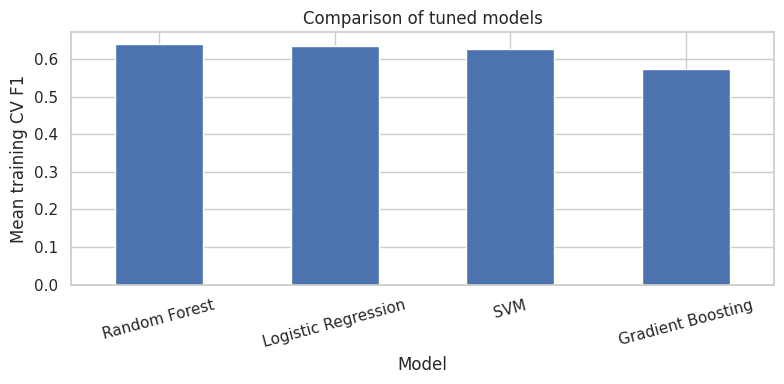

Numerical development-CV leader: Random Forest
Final retention recommendation follows after validation experiments; CV and validation scores are separate.


In [23]:
comparison.plot(x='Model', y='CV F1', kind='bar', legend=False, figsize=(8, 4))
plt.ylabel('Mean training CV F1')
plt.title('Comparison of tuned models')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_model_name = comparison.iloc[0]['Model']
best_model = trained_models[best_model_name]

cv_leader_name = best_model_name
print('Numerical development-CV leader:', cv_leader_name)
print('Final retention recommendation follows after validation experiments; CV and validation scores are separate.')

## Class-weight and undersampling evidence

Fit on development data; score on validation. Compare LR weights and random undersampling (no SMOTE).


In [24]:
experiment_models = {
    'CV-tuned Logistic Regression': clone(lr_search.best_estimator_),
    'CV-tuned Random Forest': clone(rf_search.best_estimator_),
    'CV-tuned Gradient Boosting': clone(gb_search.best_estimator_),
    'CV-tuned SVM': clone(svm_search.best_estimator_)
}

weight_options = {
    'LR C=1 unweighted': None,
    'LR C=1 balanced': 'balanced',
    'LR C=1 churn weight 2': {0: 1, 1: 2},
    'LR C=1 churn weight 3': {0: 1, 1: 3},
    'LR C=1 churn weight 4': {0: 1, 1: 4}
}

for name, weight in weight_options.items():
    experiment_models[name] = Pipeline([
        ('preprocess', clone(preprocess_scaled)),
        ('model', LogisticRegression(C=1, class_weight=weight,
            solver='liblinear', max_iter=1000, random_state=SEED))
    ])

experiment_rows = []

for name, model in experiment_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)
    experiment_rows.append({
        'Approach': name,
        'Validation accuracy': accuracy_score(y_validation, predictions),
        'Validation precision': precision_score(y_validation, predictions, zero_division=0),
        'Validation recall': recall_score(y_validation, predictions, zero_division=0),
        'Validation F1': f1_score(y_validation, predictions, zero_division=0),
        'Validation ROC-AUC': roc_auc_score(y_validation, model.predict_proba(X_validation)[:, 1]),
        'Validation AP': average_precision_score(y_validation, model.predict_proba(X_validation)[:, 1]),
        'Customers flagged': predictions.sum(),
        'Fitting rows': len(X_train)
    })


In [25]:
churn_rows = X_train.loc[y_train == 1]
stay_rows = X_train.loc[y_train == 0].sample(n=len(churn_rows), random_state=SEED)
X_under = pd.concat([churn_rows, stay_rows]).sample(frac=1, random_state=SEED)
y_under = y_train.loc[X_under.index]

undersampled_model = Pipeline([
    ('preprocess', clone(preprocess_scaled)),
    ('model', LogisticRegression(C=1, solver='liblinear', max_iter=1000, random_state=SEED))
])
undersampled_model.fit(X_under, y_under)
experiment_models['LR C=1 random undersampling'] = undersampled_model
under_predictions = undersampled_model.predict(X_validation)

experiment_rows.append({
    'Approach': 'LR C=1 random undersampling',
    'Validation accuracy': accuracy_score(y_validation, under_predictions),
    'Validation precision': precision_score(y_validation, under_predictions, zero_division=0),
    'Validation recall': recall_score(y_validation, under_predictions, zero_division=0),
    'Validation F1': f1_score(y_validation, under_predictions, zero_division=0),
    'Validation ROC-AUC': roc_auc_score(y_validation, undersampled_model.predict_proba(X_validation)[:, 1]),
    'Validation AP': average_precision_score(y_validation, undersampled_model.predict_proba(X_validation)[:, 1]),
    'Customers flagged': under_predictions.sum(),
    'Fitting rows': len(X_under)
})

experiment_table = pd.DataFrame(experiment_rows).sort_values('Validation F1', ascending=False)
display(experiment_table.round(4))
print('Development class counts:', y_train.value_counts().to_dict())
print('Undersampled class counts:', y_under.value_counts().to_dict())


,Approach,Validation accuracy,Validation precision,Validation recall,Validation F1,Validation ROC-AUC,Validation AP,Customers flagged,Fitting rows
9,LR C=1 random undersampling,0.7495,0.5185,0.7861,0.6249,0.8397,0.6506,567,2242
1,CV-tuned Random Forest,0.7502,0.5195,0.7834,0.6247,0.8390,0.6496,564,4225
6,LR C=1 churn weight 2,0.7722,0.5551,0.7139,0.6246,0.8395,0.6524,481,4225
3,CV-tuned SVM,0.7452,0.5132,0.7807,0.6193,0.8335,0.6310,569,4225
0,CV-tuned Logistic Regression,0.7445,0.5123,0.7807,0.6186,0.8395,0.6518,570,4225
5,LR C=1 balanced,0.7445,0.5123,0.7807,0.6186,0.8395,0.6518,570,4225
7,LR C=1 churn weight 3,0.7381,0.5043,0.7914,0.6160,0.8395,0.6517,587,4225
8,LR C=1 churn weight 4,0.6977,0.4620,0.8449,0.5974,0.8396,0.6514,684,4225
4,LR C=1 unweighted,0.8084,0.6818,0.5214,0.5909,0.8390,0.6520,286,4225
2,CV-tuned Gradient Boosting,0.8062,0.6823,0.5053,0.5806,0.8369,0.6462,277,4225


Development class counts: {0: 3104, 1: 1121}
Undersampled class counts: {1: 1121, 0: 1121}


### Threshold evidence for balanced and undersampled LR

Validation thresholds from 0.20 to 0.70 (step 0.05).


,Approach,Threshold,Validation accuracy,Validation precision,Validation recall,Validation F1,Customers flagged
0,LR C=1 balanced,0.20,0.5926,0.3894,0.9412,0.5509,904
1,LR C=1 balanced,0.25,0.6139,0.4005,0.9144,0.5570,854
2,LR C=1 balanced,0.30,0.6416,0.4190,0.9064,0.5731,809
3,LR C=1 balanced,0.35,0.6678,0.4375,0.8797,0.5844,752
4,LR C=1 balanced,0.40,0.6927,0.4576,0.8503,0.5949,695
5,LR C=1 balanced,0.45,0.7282,0.4928,0.8209,0.6158,623
6,LR C=1 balanced,0.50,0.7445,0.5123,0.7807,0.6186,570
7,LR C=1 balanced,0.55,0.7615,0.5373,0.7326,0.6199,510
8,LR C=1 balanced,0.60,0.7800,0.5693,0.7032,0.6292,462
9,LR C=1 balanced,0.65,0.7956,0.6054,0.6604,0.6317,408


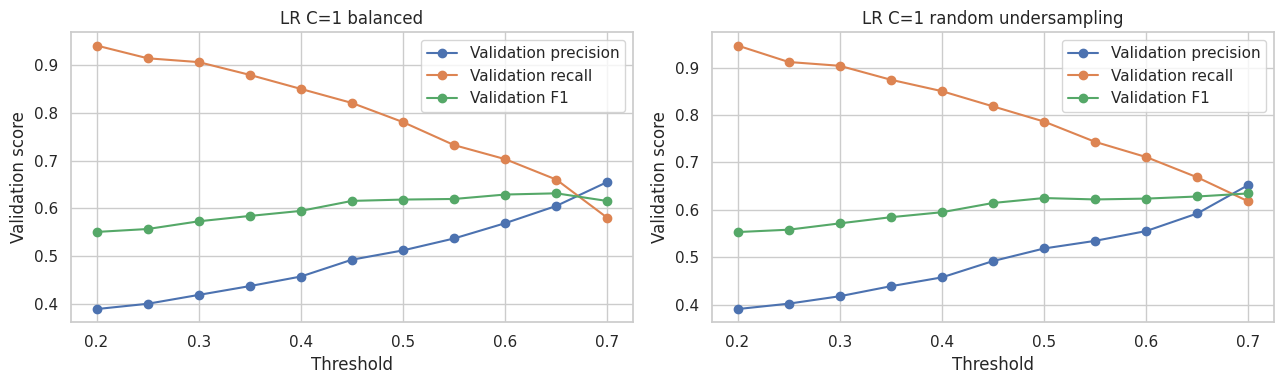

Numerical threshold-grid leader: LR C=1 random undersampling
Its cutoff: 0.7
Its validation F1: 0.6346
Its validation recall: 0.6176


In [26]:
threshold_models = {
    'LR C=1 balanced': experiment_models['LR C=1 balanced'],
    'LR C=1 random undersampling': experiment_models['LR C=1 random undersampling']
}

threshold_rows = []
for name, model in threshold_models.items():
    validation_scores = model.predict_proba(X_validation)[:, 1]
    for threshold in np.arange(0.20, 0.71, 0.05):
        threshold = round(float(threshold), 2)
        predictions = (validation_scores >= threshold).astype(int)
        threshold_rows.append({
            'Approach': name,
            'Threshold': threshold,
            'Validation accuracy': accuracy_score(y_validation, predictions),
            'Validation precision': precision_score(y_validation, predictions, zero_division=0),
            'Validation recall': recall_score(y_validation, predictions, zero_division=0),
            'Validation F1': f1_score(y_validation, predictions, zero_division=0),
            'Customers flagged': predictions.sum()
        })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for (name, data), ax in zip(threshold_table.groupby('Approach'), axes):
    data.plot(x='Threshold', y=['Validation precision', 'Validation recall', 'Validation F1'],
              marker='o', ax=ax)
    ax.set_title(name)
    ax.set_ylabel('Validation score')
plt.tight_layout()
plt.show()

threshold_best = threshold_table.sort_values('Validation F1', ascending=False).iloc[0]
print('Numerical threshold-grid leader:', threshold_best['Approach'])
print('Its cutoff:', threshold_best['Threshold'])
print('Its validation F1:', round(threshold_best['Validation F1'], 4))
print('Its validation recall:', round(threshold_best['Validation recall'], 4))


### Final recommendation: balanced Logistic Regression, native prediction

**Recommended model:** LR C=1, `class_weight='balanced'`, native `predict()` (no custom threshold, no undersampling).


In [27]:
selected_approach = 'LR C=1 balanced'
selected_candidate = experiment_models[selected_approach]
use_custom_threshold = False
selected_threshold = 0.50

recommendation_rows = experiment_table.loc[
    experiment_table['Approach'].isin([
        'CV-tuned Random Forest', 'LR C=1 balanced', 'LR C=1 random undersampling'
    ])
]
display(recommendation_rows.round(4))
print('Recommended approach:', selected_approach)
print('Reason: simple full-data model, close CV F1, and stronger validation recall than the 0.70 option.')

X_full_train = pd.concat([X_train, X_validation])
y_full_train = pd.concat([y_train, y_validation])
best_model = clone(selected_candidate)
best_model.fit(X_full_train, y_full_train)
best_model_name = selected_approach
print('Final fitting rows:', len(X_full_train))
print('Final prediction rule: native balanced LR predict(), equivalent to a 0.50 cutoff.')


,Approach,Validation accuracy,Validation precision,Validation recall,Validation F1,Validation ROC-AUC,Validation AP,Customers flagged,Fitting rows
9,LR C=1 random undersampling,0.7495,0.5185,0.7861,0.6249,0.8397,0.6506,567,2242
1,CV-tuned Random Forest,0.7502,0.5195,0.7834,0.6247,0.8390,0.6496,564,4225
5,LR C=1 balanced,0.7445,0.5123,0.7807,0.6186,0.8395,0.6518,570,4225


Recommended approach: LR C=1 balanced
Reason: simple full-data model, close CV F1, and stronger validation recall than the 0.70 option.
Final fitting rows: 5634
Final prediction rule: native balanced LR predict(), equivalent to a 0.50 cutoff.


### How to read the results

CV compares algorithms; validation compares imbalance/threshold options; section 13C states the frozen recommendation before the final test.


## Final test evaluation


In [28]:
y_score = best_model.predict_proba(X_test)[:, 1]
if use_custom_threshold:
    y_pred = (y_score >= selected_threshold).astype(int)
else:
    y_pred = best_model.predict(X_test)

test_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average precision'],
    'Value': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_score),
        average_precision_score(y_test, y_score)
    ]
})

display(test_metrics)
print(classification_report(y_test, y_pred, target_names=['Stay', 'Churn']))
print('Majority Stay baseline test accuracy:', (y_test == 0).mean())

,Metric,Value
0,Accuracy,0.740241
1,Precision,0.506689
2,Recall,0.810160
3,F1,0.623457
4,ROC-AUC,0.845509
5,Average precision,0.653964


              precision    recall  f1-score   support

        Stay       0.91      0.71      0.80      1035
       Churn       0.51      0.81      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Majority Stay baseline test accuracy: 0.7345635202271115


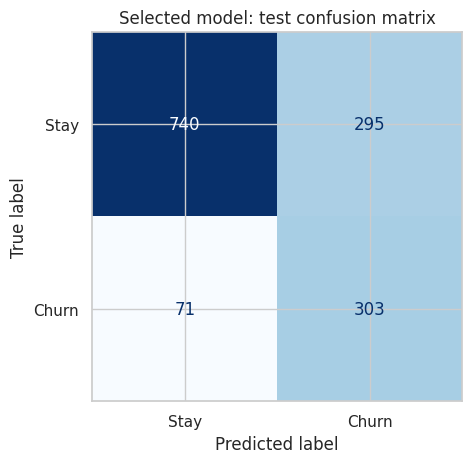

Churners found: 303
Churners missed: 71
Non-churners flagged: 295


In [29]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Stay', 'Churn']).plot(cmap='Blues', colorbar=False)
plt.title('Selected model: test confusion matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()
print('Churners found:', tp)
print('Churners missed:', fn)
print('Non-churners flagged:', fp)

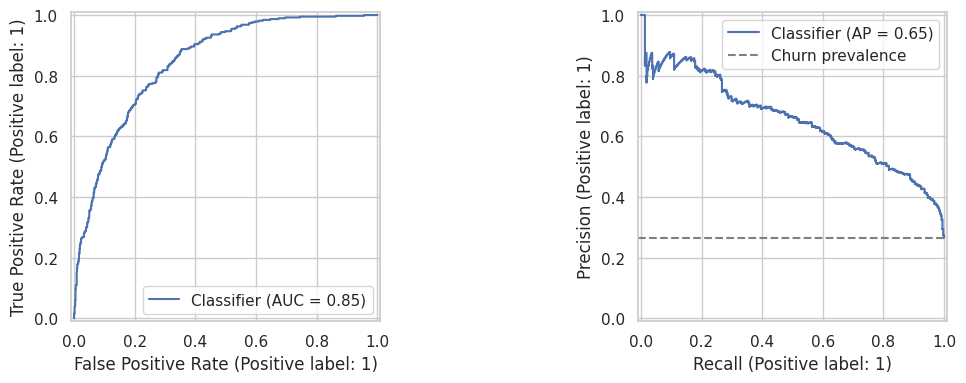

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, y_score, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, y_score, ax=axes[1])
axes[1].axhline(y_test.mean(), color='grey', linestyle='--', label='Churn prevalence')
axes[1].legend()
plt.tight_layout()
plt.show()

## Important inputs

Permutation importance on the fitted recommended model (training-pool data).


,Feature,Importance
7,InternetService,0.130600
4,tenure,0.088261
14,Contract,0.060862
21,TenureGroup,0.039627
17,MonthlyCharges,0.031089
6,MultipleLines,0.013470
20,AvgMonthlyCharge,0.010105
15,PaperlessBilling,0.009111
13,StreamingMovies,0.008816
12,StreamingTV,0.006931


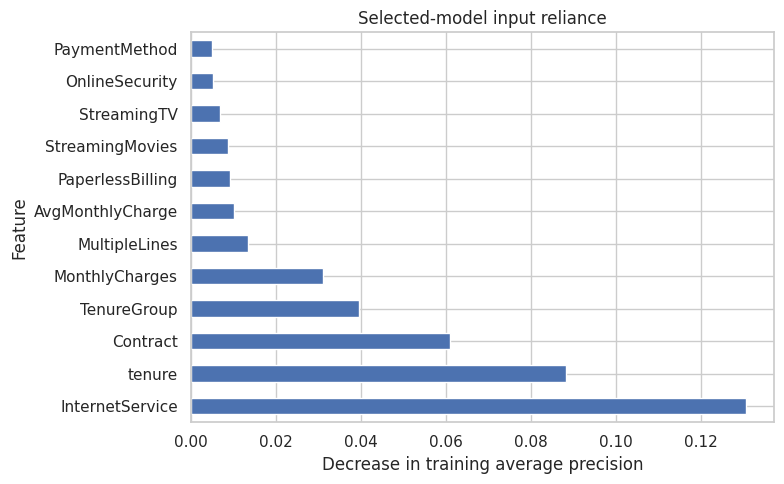

In [31]:
importance_result = permutation_importance(best_model, X_full_train, y_full_train,
    scoring='average_precision', n_repeats=3, random_state=SEED)

importance_table = pd.DataFrame({
    'Feature': X_full_train.columns,
    'Importance': importance_result.importances_mean
}).sort_values('Importance', ascending=False)

display(importance_table.head(12))
importance_table.head(12).plot(x='Feature', y='Importance', kind='barh', legend=False, figsize=(8, 5))
plt.xlabel('Decrease in training average precision')
plt.title('Selected-model input reliance')
plt.tight_layout()
plt.show()

## Secondary lens: high-risk customer profiling

Compare roughly the top 20% risk scores with the remaining test accounts.


In [32]:
test_results = X_test.copy()
test_results['ActualChurn'] = y_test
test_results['PredictedChurn'] = y_pred
test_results['RiskScore'] = y_score

ranked_customers = test_results.sort_values('RiskScore', ascending=False)
profile_count = int(0.20 * len(ranked_customers))
high_risk = ranked_customers.head(profile_count)
other_customers = ranked_customers.iloc[profile_count:]

profile = pd.DataFrame({
    'Attribute': ['Month-to-month proportion', 'Fibre optic proportion', 'Electronic check proportion',
                  'No OnlineSecurity proportion', 'Mean tenure', 'Mean add-on count'],
    'Top 20% ranked': [
        (high_risk['Contract'] == 'Month-to-month').mean(),
        (high_risk['InternetService'] == 'Fiber optic').mean(),
        (high_risk['PaymentMethod'] == 'Electronic check').mean(),
        (high_risk['OnlineSecurity'] == 'No').mean(),
        high_risk['tenure'].mean(),
        high_risk['NumAddonServices'].mean()
    ],
    'Remaining customers': [
        (other_customers['Contract'] == 'Month-to-month').mean(),
        (other_customers['InternetService'] == 'Fiber optic').mean(),
        (other_customers['PaymentMethod'] == 'Electronic check').mean(),
        (other_customers['OnlineSecurity'] == 'No').mean(),
        other_customers['tenure'].mean(),
        other_customers['NumAddonServices'].mean()
    ]
})

display(profile)
print('Accounts in the profile group:', len(high_risk))

,Attribute,Top 20% ranked,Remaining customers
0,Month-to-month proportion,0.992883,0.437943
1,Fibre optic proportion,0.854093,0.330674
2,Electronic check proportion,0.729537,0.238475
3,No OnlineSecurity proportion,0.953737,0.660461
4,Mean tenure,8.982206,37.628546
5,Mean add-on count,1.391459,2.098404


Accounts in the profile group: 281


## Outreach with a limited budget

Contact the top 30% of ranked test accounts; report precision, recall-at-capacity, and lift.


In [33]:
contact_count = int(0.30 * len(ranked_customers))
contact_list = ranked_customers.head(contact_count)

churners_in_list = contact_list['ActualChurn'].sum()
list_precision = churners_in_list / contact_count
list_recall = churners_in_list / y_test.sum()
lift = list_precision / y_test.mean()

print('Customers to contact:', contact_count)
print('Observed churners in list:', churners_in_list)
print('Precision of contact list:', round(list_precision, 4))
print('Recall at contact capacity:', round(list_recall, 4))
print('Lift compared with random contact:', round(lift, 2))

Customers to contact: 422
Observed churners in list: 243
Precision of contact list: 0.5758
Recall at contact capacity: 0.6497
Lift compared with random contact: 2.17


## Simple demographic diagnostic

Recall and false-positive rate by gender and senior status (audit only).


In [34]:
fairness_results = []

for column in ['gender', 'SeniorCitizen']:
    for group, data in test_results.groupby(column):
        group_cm = confusion_matrix(data['ActualChurn'], data['PredictedChurn'], labels=[0, 1])
        group_tn, group_fp, group_fn, group_tp = group_cm.ravel()

        fairness_results.append({
            'Column': column,
            'Group': group,
            'Accounts': len(data),
            'Actual churners': group_tp + group_fn,
            'Actual non-churners': group_tn + group_fp,
            'Recall / TPR': group_tp / (group_tp + group_fn),
            'False-positive rate': group_fp / (group_fp + group_tn)
        })

fairness_table = pd.DataFrame(fairness_results)
display(fairness_table)

,Column,Group,Accounts,Actual churners,Actual non-churners,Recall / TPR,False-positive rate
0,gender,Female,687,193,494,0.797927,0.281377
1,gender,Male,722,181,541,0.823204,0.288355
2,SeniorCitizen,0,1187,276,911,0.764493,0.252470
3,SeniorCitizen,1,222,98,124,0.938776,0.524194


##  Save and reload the model and prediction rule


In [36]:
model_bundle = {
    'model': best_model,
    'use_custom_threshold': use_custom_threshold,
    'threshold': selected_threshold,
    'approach': selected_approach
}
joblib.dump(model_bundle, 'churn_model.joblib')

loaded_bundle = joblib.load('churn_model.joblib')
loaded_model = loaded_bundle['model']
if loaded_bundle['use_custom_threshold']:
    loaded_scores = loaded_model.predict_proba(X_test)[:, 1]
    loaded_predictions = (loaded_scores >= loaded_bundle['threshold']).astype(int)
else:
    loaded_predictions = loaded_model.predict(X_test)

print('Reloaded predictions match:', np.array_equal(y_pred, loaded_predictions))

Reloaded predictions match: True


### Export evidence for the report


In [37]:
comparison.to_csv('model_comparison.csv', index=False)
test_metrics.to_csv('test_metrics.csv', index=False)
feature_comparison.to_csv('feature_comparison.csv', index=False)
eda_log.to_csv('eda_insight_log.csv', index=False)
profile.to_csv('high_risk_profile.csv', index=False)
fairness_table.to_csv('fairness_audit.csv', index=False)
outlier_table.to_csv('outlier_analysis.csv', index=False)
categorical_summary.to_csv('categorical_eda.csv', index=False)
importance_table.to_csv('feature_importance.csv', index=False)
print('Evidence tables saved.')
experiment_table.to_csv('imbalance_experiments.csv', index=False)
threshold_table.to_csv('threshold_experiments.csv', index=False)

Evidence tables saved.


## Final recommendation and measured evidence

**Recommended prototype:** balanced Logistic Regression, C=1, native prediction.

| Measure | Result |
|---|---:|
| Accuracy | 74.02% |
| Churn precision | 50.67% |
| Churn recall | 81.02% |
| F1 | 0.6235 |
| ROC-AUC | 0.8455 |
| Average precision | 0.6540 |


